In [ ]:
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p ~/.kaggle && cp /content/drive/MyDrive/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip install -q -U kaggle
!df -h /content

Mounted at /content/drive
Filesystem      Size  Used Avail Use% Mounted on
overlay         236G   89M  236G   1% /


In [ ]:
!kaggle datasets download -d steubk/wikiart -p /content/wikiart_raw
!ls -lh /content/wikiart_raw/

Dataset URL: https://www.kaggle.com/datasets/steubk/wikiart
License(s): CC0-1.0
100% 31.4G/31.4G [28:35<00:00, 19.6MB/s]

total 32G
-rw-r--r-- 1 root root 32G Sep 14  2022 wikiart.zip


In [ ]:
!mkdir -p /content/work && cd /content/work && unzip -q -o /content/drive/MyDrive/gan285_v1.zip
%cd /content/work/gan285

/content/work/gan285


In [ ]:
!python prepare_wikiart.py --zip /content/wikiart_raw/wikiart.zip --out_dir /content/drive/MyDrive/gan285/data

zip: /content/wikiart_raw/wikiart.zip，图片 81444 张，12 个进程
  5000/81444  跳过 0  7s
  10000/81444  跳过 0  12s
  15000/81444  跳过 0  17s
  20000/81444  跳过 0  23s
  25000/81444  跳过 0  28s
  30000/81444  跳过 0  34s
  35000/81444  跳过 0  40s
  40000/81444  跳过 0  46s
  45000/81444  跳过 0  51s
  50000/81444  跳过 0  57s
  55000/81444  跳过 0  63s
  60000/81444  跳过 0  69s
  65000/81444  跳过 0  75s
  70000/81444  跳过 0  80s
  75000/81444  跳过 0  86s
  80000/81444  跳过 0  92s
  81444/81444  跳过 0  93s
完成：保留 81444 张，跳过 0 张，27 个风格，用时 95s
保存在 /content/drive/MyDrive/gan285/data


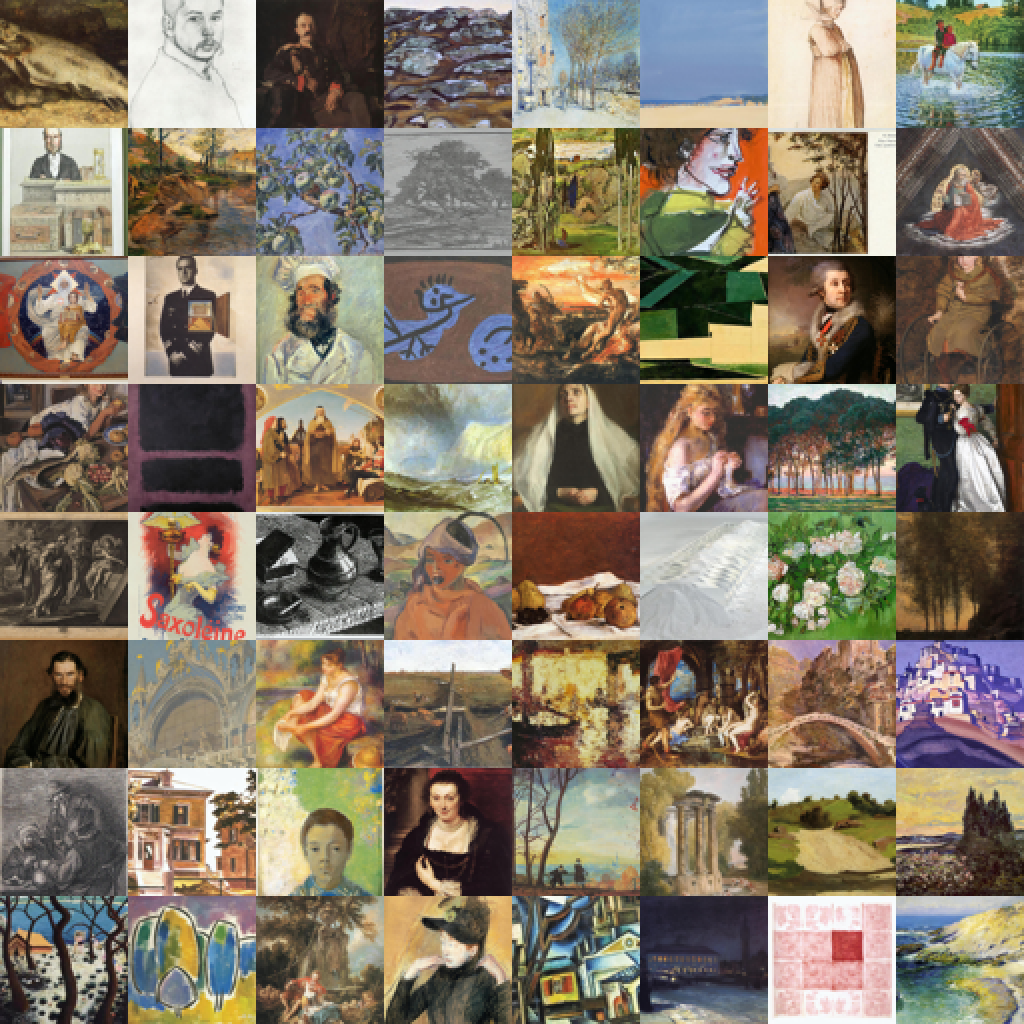

In [5]:
from IPython.display import Image
Image('/content/drive/MyDrive/gan285/data/real_grid.png')

In [ ]:
!python train_gan.py --data_dir /content/drive/MyDrive/gan285/data --out_dir /content/drive/MyDrive/gan285/run

数据: 81444 张，(3, 64, 64)
G 参数 3.58M，D 参数 2.77M
step   1000/40000  D -11.317  G +58.851  W距离 14.470  GP 0.315  每1000步 84s
step   2000/40000  D -9.113  G +46.295  W距离 11.572  GP 0.246  每1000步 75s
step   3000/40000  D -7.479  G +52.921  W距离 9.377  GP 0.190  每1000步 76s
step   4000/40000  D -6.489  G +51.568  W距离 8.139  GP 0.165  每1000步 74s
step   5000/40000  D -6.168  G +56.121  W距离 7.606  GP 0.144  每1000步 76s
step   6000/40000  D -5.600  G +51.810  W距离 6.982  GP 0.138  每1000步 75s
step   7000/40000  D -5.020  G +46.639  W距离 6.206  GP 0.119  每1000步 76s
step   8000/40000  D -4.699  G +46.205  W距离 5.732  GP 0.103  每1000步 75s
step   9000/40000  D -4.371  G +39.953  W距离 5.319  GP 0.095  每1000步 76s
step  10000/40000  D -4.218  G +34.103  W距离 5.085  GP 0.087  每1000步 74s
step  11000/40000  D -4.055  G +27.038  W距离 4.765  GP 0.071  每1000步 76s
step  12000/40000  D -3.766  G +20.584  W距离 4.656  GP 0.089  每1000步 74s
step  13000/40000  D -3.567  G +15.103  W距离 4.190  GP 0.062  每1000步 75s
step  14000/400

In [7]:
!pip install -q pytorch-ignite
!python eval_gan.py --data_dir /content/drive/MyDrive/gan285/data --run_dir /content/drive/MyDrive/gan285/run

生成器: G_final.pt（第 40000 步）
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100% 104M/104M [00:00<00:00, 240MB/s] 
FID 0.03   IS 2.873   （真实图 IS 3.930）   各 10000 张
结果保存在 /content/drive/MyDrive/gan285/run


In [8]:
!cp /content/drive/MyDrive/gan285/eval_gan.py /content/work/gan285/
%cd /content/work/gan285
!python eval_gan.py --data_dir /content/drive/MyDrive/gan285/data --run_dir /content/drive/MyDrive/gan285/run

cp: cannot stat '/content/drive/MyDrive/gan285/eval_gan.py': No such file or directory
/content/work/gan285
生成器: G_final.pt（第 40000 步）
FID 0.03   IS 2.873   （真实图 IS 3.930）   各 10000 张
结果保存在 /content/drive/MyDrive/gan285/run


In [9]:
%%writefile /content/work/gan285/eval_gan.py
import argparse, json, os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore
from ignite.metrics.gan.utils import InceptionModel
from train_gan import Generator, save_grid

parser = argparse.ArgumentParser()
parser.add_argument("--data_dir", type=str, default="data")
parser.add_argument("--run_dir", type=str, default="run")
parser.add_argument("--ckpt", type=str, default="G_final.pt")
parser.add_argument("--n", type=int, default=10000)
parser.add_argument("--batch_size", type=int, default=200)
parser.add_argument("--seed", type=int, default=42)
args = parser.parse_args()


def to_299(x):
    #[-1,1] -> [0,1] -> 299x299
    return F.interpolate((x.clamp(-1, 1) + 1) / 2, size=(299, 299), mode="bilinear", align_corners=False)


if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ck = torch.load(os.path.join(args.run_dir, args.ckpt), map_location=device, weights_only=False)
    cfg = ck["config"]
    G = Generator(cfg["nz"], cfg["ngf"]).to(device)
    G.load_state_dict(ck["G"])
    G.eval()
    print("生成器: {}（第 {} 步）".format(args.ckpt, ck["step"]))

    data = np.load(os.path.join(args.data_dir, "wikiart64.npy"), mmap_mode="r")
    rng = np.random.default_rng(args.seed)
    idx = np.sort(rng.choice(len(data), args.n, replace=False))
    real = torch.from_numpy(np.ascontiguousarray(data[idx])).permute(0, 3, 1, 2).float().div(127.5).sub(1.0)
    loader = DataLoader(TensorDataset(real), batch_size=args.batch_size, shuffle=False)
    zgen = torch.Generator(device=device).manual_seed(args.seed)

    def evaluation_step(engine, batch):
        with torch.no_grad():
            r = batch[0].to(device)
            z = torch.randn(r.shape[0], cfg["nz"], generator=zgen, device=device)
            return to_299(G(z)), to_299(r)

    evaluator = Engine(evaluation_step)
    FID(device=device).attach(evaluator, "fid")                      #ignite 默认：1000 维 softmax 概率
    FID(num_features=2048, feature_extractor=InceptionModel(return_features=True, device=device),
        device=device).attach(evaluator, "fid_2048")                 #标准：2048 维池化特征
    InceptionScore(device=device, output_transform=lambda x: x[0]).attach(evaluator, "is")
    InceptionScore(device=device, output_transform=lambda x: x[1]).attach(evaluator, "is_real")
    evaluator.run(loader, max_epochs=1)
    m = evaluator.state.metrics

    res = {"fid": float(m["fid"]), "fid_2048": float(m["fid_2048"]), "is": float(m["is"]),
           "is_real": float(m["is_real"]), "n_fake": args.n, "n_real": args.n, "ckpt": args.ckpt,
           "step": ck["step"], "resize": "bilinear to 299x299, inputs in [0,1]"}
    json.dump(res, open(os.path.join(args.run_dir, "eval.json"), "w"), indent=1)
    print("FID（ignite 默认，1000 维 softmax）{:.4f}   FID（标准，2048 维池化特征）{:.2f}   IS {:.3f}   （真实图 IS {:.3f}）   各 {} 张".format(
        res["fid"], res["fid_2048"], res["is"], res["is_real"], args.n))

    with torch.no_grad():
        z = torch.randn(100, cfg["nz"], generator=torch.Generator().manual_seed(args.seed)).to(device)
        fake = G(z)
    save_grid(fake, os.path.join(args.run_dir, "samples_final.png"), nrow=8)
    save_grid(fake, os.path.join(args.run_dir, "samples_large.png"), nrow=10)
    print("结果保存在", args.run_dir)

Overwriting /content/work/gan285/eval_gan.py


In [10]:
%cd /content/work/gan285
!python eval_gan.py --data_dir /content/drive/MyDrive/gan285/data --run_dir /content/drive/MyDrive/gan285/run

/content/work/gan285
生成器: G_final.pt（第 40000 步）
FID（ignite 默认，1000 维 softmax）0.0255   FID（标准，2048 维池化特征）24.10   IS 2.873   （真实图 IS 3.930）   各 10000 张
结果保存在 /content/drive/MyDrive/gan285/run


In [11]:
!cd /content/drive/MyDrive/gan285/run && zip -q /content/gan_report_files.zip loss_curves.png samples_final.png samples_large.png config.json eval.json train_log.csv samples/step_002000.png samples/step_010000.png samples/step_040000.png
from google.colab import files
files.download('/content/gan_report_files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>